<a href="https://colab.research.google.com/github/AmirthaaR/credit-card-fraud-detection/blob/main/Credit_Card_Fraud_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

uploaded = files.upload()

Saving creditcard.csv to creditcard.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("creditcard.csv")

print("Dataset shape:", df.shape)
display(df.head())
print(df.info())

Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [3]:
print(df["Class"].value_counts())

print("\nPercentage of each class:")
print(df["Class"].value_counts(normalize=True) * 100)

Class
0    284315
1       492
Name: count, dtype: int64

Percentage of each class:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


# *Exploratory Data Analysis*

Missing values: 0

Dataset shape: (284807, 31)

Statistical summary:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


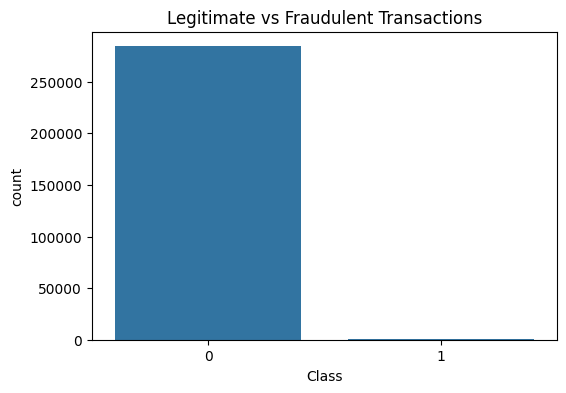

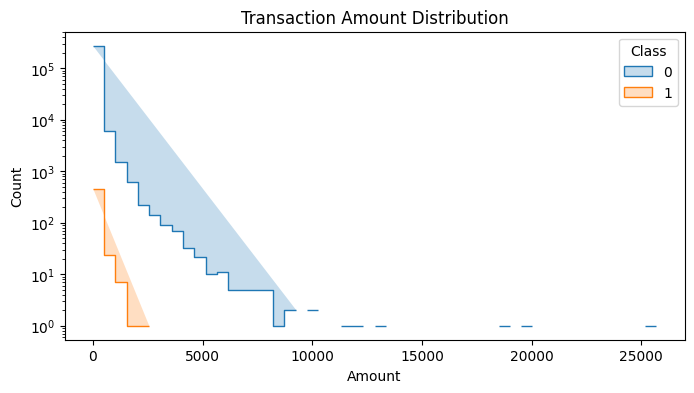

In [4]:
print("Missing values:", df.isnull().sum().sum())

print("\nDataset shape:", df.shape)

print("\nStatistical summary:")
display(df.describe())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Class")
plt.title("Legitimate vs Fraudulent Transactions")
plt.show()

plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="Amount", hue="Class",
             bins=50, log_scale=(False, True),
             element="step", stat="count",
             common_norm=False)
plt.title("Transaction Amount Distribution")
plt.show()

# *Prepare the data and train the model*

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()

X_train[["Time", "Amount"]] = scaler.fit_transform(
    X_train[["Time", "Amount"]]
)

X_test[["Time", "Amount"]] = scaler.transform(
    X_test[["Time", "Amount"]]
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTraining class distribution:")
print(y_train.value_counts())
print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 227845
Testing samples: 56962

Training class distribution:
Class
0    227451
1       394
Name: count, dtype: int64

Testing class distribution:
Class
0    56864
1       98
Name: count, dtype: int64


In [6]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model training completed!")

Model training completed!


              precision    recall  f1-score   support

           0     0.9999    0.9756    0.9876     56864
           1     0.0610    0.9184    0.1144        98

    accuracy                         0.9755     56962
   macro avg     0.5304    0.9470    0.5510     56962
weighted avg     0.9982    0.9755    0.9861     56962



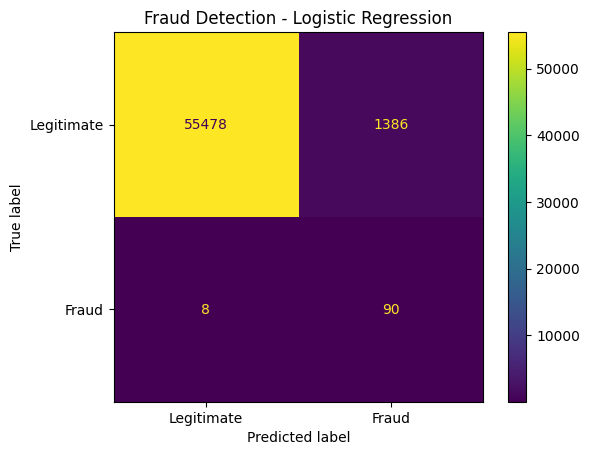

In [7]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print(classification_report(
    y_test, y_pred, digits=4, zero_division=0
))

cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Fraud"]
).plot()

plt.title("Fraud Detection - Logistic Regression")
plt.show()

# *Improve the model*

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print(classification_report(
    y_test, rf_pred, digits=4, zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

              precision    recall  f1-score   support

           0     0.9996    0.9999    0.9998     56864
           1     0.9605    0.7449    0.8391        98

    accuracy                         0.9995     56962
   macro avg     0.9800    0.8724    0.9194     56962
weighted avg     0.9995    0.9995    0.9995     56962

Confusion Matrix:
[[56861     3]
 [   25    73]]


# *Improve fraud detection using threshold tuning*

In [9]:
from sklearn.metrics import precision_score, recall_score, f1_score

rf_prob = rf_model.predict_proba(X_test)[:, 1]

for threshold in [0.5, 0.3, 0.2, 0.1]:
    pred = (rf_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision_score(y_test, pred), 4))
    print("Recall:", round(recall_score(y_test, pred), 4))
    print("F1-score:", round(f1_score(y_test, pred), 4))


Threshold: 0.5
Precision: 0.9605
Recall: 0.7449
F1-score: 0.8391

Threshold: 0.3
Precision: 0.9222
Recall: 0.8469
F1-score: 0.883

Threshold: 0.2
Precision: 0.8571
Recall: 0.8571
F1-score: 0.8571

Threshold: 0.1
Precision: 0.7414
Recall: 0.8776
F1-score: 0.8037


# *Validate the threshold correctly*

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

X = df.drop("Class", axis=1)
y = df["Class"]

X_dev, X_test_final, y_dev, y_test_final = train_test_split(
    X, y, test_size=0.2, random_state=123, stratify=y
)

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=123, stratify=y_dev
)

scaler_final = StandardScaler()
cols = ["Time", "Amount"]

X_train_final = X_train_final.copy()
X_val = X_val.copy()
X_test_final = X_test_final.copy()

X_train_final.loc[:, cols] = scaler_final.fit_transform(X_train_final[cols])
X_val.loc[:, cols] = scaler_final.transform(X_val[cols])
X_test_final.loc[:, cols] = scaler_final.transform(X_test_final[cols])

rf_final = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_final.fit(X_train_final, y_train_final)

val_prob = rf_final.predict_proba(X_val)[:, 1]

best_threshold = 0.3
val_pred = (val_prob >= best_threshold).astype(int)

print("Validation report:")
print(classification_report(y_val, val_pred, digits=4))

test_prob = rf_final.predict_proba(X_test_final)[:, 1]
test_pred = (test_prob >= best_threshold).astype(int)

print("Final test report:")
print(classification_report(y_test_final, test_pred, digits=4))
print("Final confusion matrix:")
print(confusion_matrix(y_test_final, test_pred))

Validation report:
              precision    recall  f1-score   support

           0     0.9997    0.9998    0.9998     56863
           1     0.9011    0.8283    0.8632        99

    accuracy                         0.9995     56962
   macro avg     0.9504    0.9141    0.9315     56962
weighted avg     0.9995    0.9995    0.9995     56962

Final test report:
              precision    recall  f1-score   support

           0     0.9995    0.9998    0.9997     56864
           1     0.8765    0.7245    0.7933        98

    accuracy                         0.9994     56962
   macro avg     0.9380    0.8622    0.8965     56962
weighted avg     0.9993    0.9994    0.9993     56962

Final confusion matrix:
[[56854    10]
 [   27    71]]


# *Save the model*

In [11]:
import joblib

joblib.dump(rf_final, "fraud_detection_model.pkl")
joblib.dump(scaler_final, "fraud_scaler.pkl")

print("Model and scaler saved successfully!")

Model and scaler saved successfully!


In [12]:
from google.colab import files

files.download("fraud_detection_model.pkl")
files.download("fraud_scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>